In [1]:
%reload_ext autoreload
%autoreload 2

from turbos.sim.p3d.p3d import P3D
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np

run = P3D(
    "/archive/tulasi/MEGARUNS_DATA_SUBSET/149p6",
    filenum="000",
)
# #419
# ds = run.load_xarray(419, variables=['J', 'Ji', 'Je', 'E', 'ne', 'ni'])
# print(ds)
ds = xr.open_dataset('../data/149p6_rs.nc')
print(ds.keys())

KeysView(<xarray.Dataset> Size: 6GB
Dimensions:  (x: 4096, y: 4096, c: 3, i: 3, j: 3)
Coordinates:
  * x        (x) float64 33kB 0.0 0.03651 0.07303 0.1095 ... 149.5 149.5 149.5
  * y        (y) float64 33kB 0.0 0.03651 0.07303 0.1095 ... 149.5 149.5 149.5
  * c        (c) <U1 12B 'x' 'y' 'z'
  * i        (i) <U1 12B 'x' 'y' 'z'
  * j        (j) <U1 12B 'x' 'y' 'z'
Data variables:
    B        (x, y, c) float64 403MB ...
    E        (x, y, c) float64 403MB ...
    J        (x, y, c) float64 403MB ...
    Je       (x, y, c) float64 403MB ...
    Ji       (x, y, c) float64 403MB ...
    ue       (x, y, c) float64 403MB ...
    ui       (x, y, c) float64 403MB ...
    Pe       (x, y, i, j) float64 1GB ...
    Pi       (x, y, i, j) float64 1GB ...
    ne       (x, y) float64 134MB ...
    ni       (x, y) float64 134MB ...
    rho      (x, y) float64 134MB ...
Attributes:
    time:        0.0
    run:         149p6_rs
    snapshot:    0
    format:      movie
    n_averaged:  120)


In [2]:
# from turbos.filter import kfilter
# kf = 20

# ds['Ji'] = kfilter(ds['Ji'], kf)
# ds['Je'] = kfilter(ds['Je'], kf)
# ds['ne'] = kfilter(ds['ne'], kf)
# ds['ni'] = kfilter(ds['ni'], kf)
# ds['E']  = kfilter(ds['E'] , kf)

In [3]:
from scipy.ndimage import uniform_filter, gaussian_filter

def coarse_grain(field, ell, dx, dy, kind='boxcar'):
    """Centered 2D filter with periodic boundary conditions.

    For boxcar, ell is the approximate filter width in both x and y.
    For Gaussian, ell is sigma in each spatial direction (one convention).
    """
    if ell == 0:
        return field
    if kind == 'boxcar':
        def odd_width(width):
            n = max(1, int(round(width)))
            return n if n % 2 else n + 1
        widths = (odd_width(ell / dx), odd_width(ell / dy))
        return uniform_filter(field, size=widths, mode='wrap')
    elif kind == 'gaussian':
        return gaussian_filter(field, sigma=(ell / dx, ell / dy),
                               mode='wrap', truncate=4.0)
    else:
        raise ValueError("kind must be 'boxcar' or 'gaussian'")

In [ ]:

import numpy as np
import xarray as xr
import json

dx = (ds.x[1] - ds.x[0]).values
dy = (ds.y[1] - ds.y[0]).values

n = 20
ells = np.logspace(np.log10(5e-2), np.log10(70), num=n)

l_filter = {
    "Pi_bb": [],
    "Pi_bb_i": [],
    "Pi_bb_e": [],
    # "JE_resolved": [],
    # "JeE_resolved": [],
    # "JiE_resolved": [],
    "Lambda_ub": [],
    "Lambda_ub_e": [],
    "Lambda_ub_i": [],
}

for num, ell in enumerate(ells):
    print(num, ell)

    # Filter species densities
    ni_bar = coarse_grain(ds["ni"], ell, dx, dy, kind="boxcar")
    ne_bar = coarse_grain(ds["ne"], ell, dx, dy, kind="boxcar")

    # Initialize filtered vector fields
    Ji_bar = xr.zeros_like(ds["Ji"])
    Je_bar = xr.zeros_like(ds["Je"])
    E_bar = xr.zeros_like(ds["E"])

    Ei_sgs = xr.zeros_like(ds["E"])
    Ee_sgs = xr.zeros_like(ds["E"])

    for i in range(3):

        comp = ds["E"].c.values[i]

        # Filter current densities
        ji_bar = coarse_grain(
            ds["Ji"].isel(c=i),
            ell, dx, dy, kind="boxcar"
        )

        je_bar = coarse_grain(
            ds["Je"].isel(c=i),
            ell, dx, dy, kind="boxcar"
        )

        # Filter electric field
        e_bar = coarse_grain(
            ds["E"].isel(c=i),
            ell, dx, dy, kind="boxcar"
        )

        # Favre-filtered electric fields
        ei_tilde = coarse_grain(
            ds["ni"] * ds["E"].isel(c=i),
            ell, dx, dy, kind="boxcar"
        ) / ni_bar

        ee_tilde = coarse_grain(
            ds["ne"] * ds["E"].isel(c=i),
            ell, dx, dy, kind="boxcar"
        ) / ne_bar

        # Save filtered components
        Ji_bar.loc[{"c": comp}] = ji_bar
        Je_bar.loc[{"c": comp}] = je_bar
        E_bar.loc[{"c": comp}] = e_bar

        # SGS electric-field corrections
        Ei_sgs.loc[{"c": comp}] = ei_tilde - e_bar
        Ee_sgs.loc[{"c": comp}] = ee_tilde - e_bar

    # Species electromagnetic SGS flux
    Pi_bb_i = -(Ji_bar * Ei_sgs).sum("c")
    Pi_bb_e = -(Je_bar * Ee_sgs).sum("c")

    # Total SGS flux
    Pi_bb = Pi_bb_i + Pi_bb_e

    # Resolved electric work
    J_bar = Ji_bar + Je_bar
    JE_resolved = (J_bar * E_bar).sum("c")
    JeE_resolved = (Je_bar * E_bar).sum("c")
    JiE_resolved = (Ji_bar * E_bar).sum("c")

    # Yang's filtered electromagnetic-bulk-flow exchange
    Lambda_ub = Pi_bb - JE_resolved
    Lambda_ub_e = Pi_bb_e - JeE_resolved
    Lambda_ub_i = Pi_bb_i - JiE_resolved

    # Spatial averages
    l_filter["Pi_bb"].append(
        float(Pi_bb.mean(("x", "y")).values)
    )
    l_filter["Pi_bb_i"].append(
        float(Pi_bb_i.mean(("x", "y")).values)
    )
    l_filter["Pi_bb_e"].append(
        float(Pi_bb_e.mean(("x", "y")).values)
    )
    # l_filter["JE_resolved"].append(
    #     float(JE_resolved.mean(("x", "y")).values)
    # )
    # l_filter["JeE_resolved"].append(
    #     float(JeE_resolved.mean(("x", "y")).values)
    # )    
    # l_filter["JiE_resolved"].append(
    #     float(JiE_resolved.mean(("x", "y")).values)
    # )
    l_filter["Lambda_ub_e"].append(
        float(Lambda_ub_e.mean(("x", "y")).values)
    )
    l_filter["Lambda_ub_i"].append(
        float(Lambda_ub_i.mean(("x", "y")).values)
    )
    l_filter["Lambda_ub"].append(
        float(Lambda_ub.mean(("x", "y")).values)
    )

# Save results
json_output = json.dumps(l_filter, indent=4)
print(json_output)

with open("../data/l_filter_SGS_JE.json", "w") as f:
    f.write(json_output)


0 0.049999999999999996
1 0.07320751926040012
2 0.10718681752523715
3 0.15693762016879584
4 0.22978027702376966
5 0.336432881117554
6 0.49258833248490475
7 0.7212233967567413
8 1.0559795141824069
9 1.5461128124619303
10 2.2637416699411643
11 3.314458238055763
12 4.8528653060051825
13 7.105324607150042
14 10.403263760586638
15 15.231942642483371
16 22.30185468745824
17 32.653269131494895
18 47.809296577178806
19 70.00000000000001
{
    "Pi_bb": [
        1.061208617002789e-22,
        2.3712851157884305e-07,
        2.3712851157884305e-07,
        3.190887192025723e-07,
        4.074134248859212e-07,
        5.133800411535901e-07,
        7.631720865370563e-07,
        1.3218389352529908e-06,
        1.8300999473618313e-06,
        2.3394868755312126e-06,
        2.1995513034537692e-06,
        1.2120917162007204e-06,
        4.051984509268458e-09,
        -8.125864923751619e-07,
        -1.502123627390327e-06,
        -1.8626807849483511e-06,
        -1.4043897484588004e-06,
        -7.

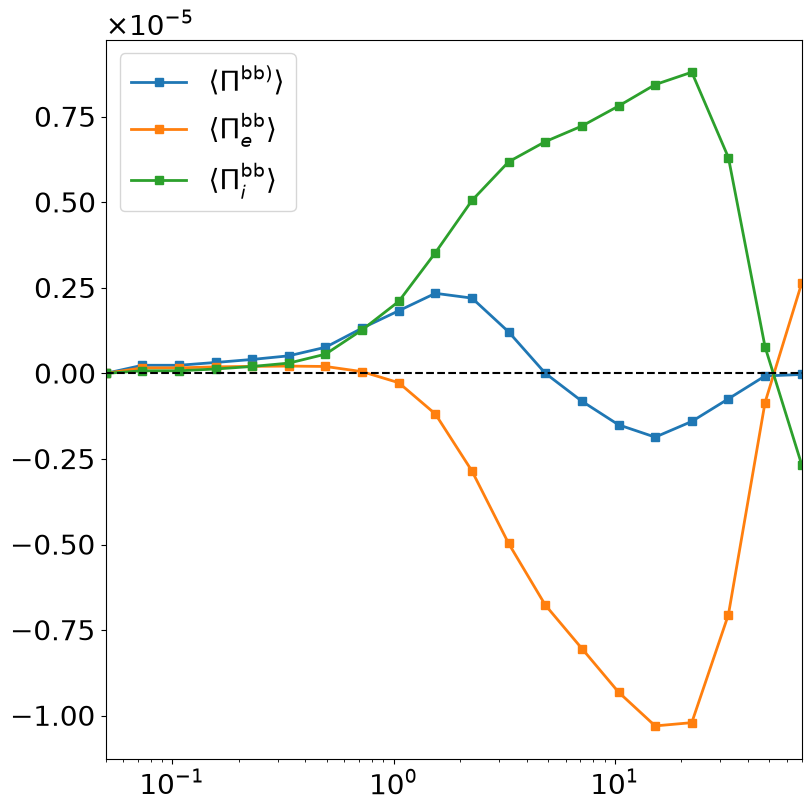

In [10]:
fig, ax = plt.subplots(figsize=(8, 8), layout = 'constrained')
plt.rcParams.update({'font.size': 20})
ax.ticklabel_format(axis="both", style="sci", scilimits=(0, 0), useMathText=True)

n = 20
ax.semilogx(ells, l_filter['Pi_bb'] , marker = 's', color='tab:blue', lw=2, label=r'$\langle \Pi^{\mathrm{b b})}\rangle$')
ax.semilogx(ells, l_filter['Pi_bb_i'], marker = 's', color='tab:orange', lw=2, label=r'$\langle \Pi_{e}^{\mathrm{b b}}\rangle$')
ax.semilogx(ells, l_filter['Pi_bb_e'], marker = 's', color='tab:green', lw=2, label=r'$\langle \Pi_{i}^{\mathrm{b b}}\rangle$')
ax.axhline(0, ls = '--', c = 'black')
# ax.set_ylim(-1e-5, 9e-5)
ax.set_xlim(5e-2, 70)

ax.legend(loc = 'upper left')



fig.savefig('../fig/SF_Pi.png', dpi = 300)

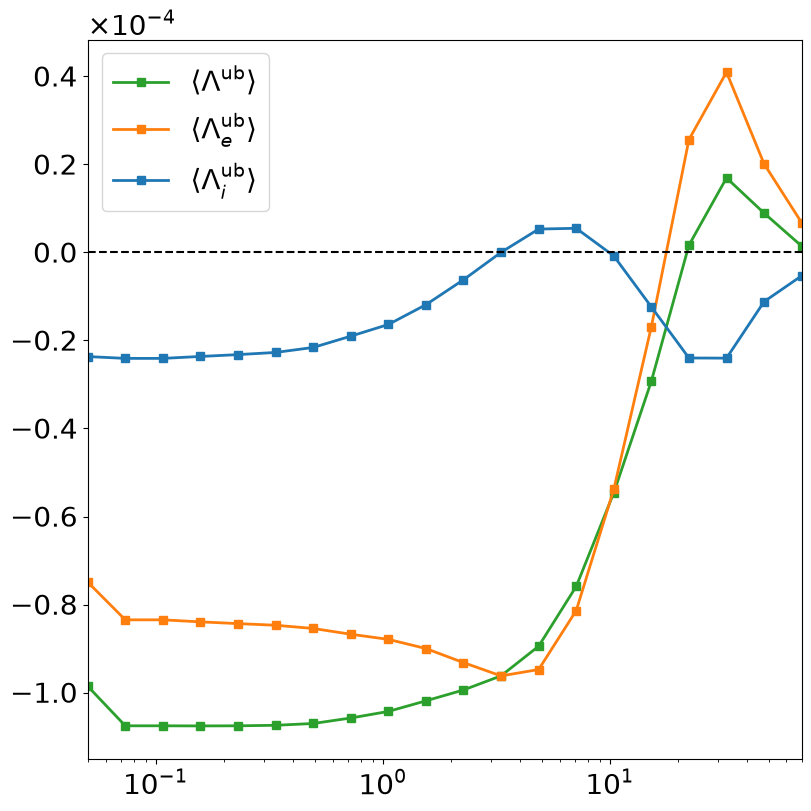

In [11]:
fig, ax = plt.subplots(figsize=(8, 8), layout = 'constrained')
plt.rcParams.update({'font.size': 20})
ax.ticklabel_format(axis="both", style="sci", scilimits=(0, 0), useMathText=True)

n = 20
# ax.semilogx(ells, l_filter['JE_resolved'] , marker = 's', color='tab:blue', lw=2, label=r'$\langle \Pi^{\mathrm{b b})}\rangle$')
ax.semilogx(ells, l_filter['Lambda_ub'], marker = 's', color='tab:green', lw=2, label=r'$\langle \Lambda^{\mathrm{u b}}\rangle$')
ax.semilogx(ells, l_filter['Lambda_ub_e'], marker = 's', color='tab:orange', lw=2, label=r'$\langle \Lambda_{e}^{\mathrm{u b}}\rangle$')
ax.semilogx(ells, l_filter['Lambda_ub_i'], marker = 's', color='tab:blue', lw=2, label=r'$\langle \Lambda_{i}^{\mathrm{u b}}\rangle$')
ax.axhline(0, ls = '--', c = 'black')
# ax.set_ylim(-1e-5, 9e-5)
ax.set_xlim(5e-2, 70)

ax.legend(loc = 'upper left')



fig.savefig('../fig/SF_Lambda.png', dpi = 300)


